In [1]:
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
#读取并检查数据
ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
ds

<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (time, lat, lon) float32 2MB ...
    column_averaging_kernel  (time, pressure, lat, lon) float32 22MB ...
    vmr_profile_ch4_apriori  (time, pressure, lat, lon) float32 22MB ...
Attributes: (12/28)
    activity_id:            obs4MIPs
    comment:                Since long time, climate modellers use ensemble a...
    contact:                Maximilian Reuter (maximilian.reuter@iup.physik.u...
    Conventions:            CF-1.7 ODS-2.1
    creation_date:          2021-02-05T09:48:47Z
    data_specs_version:     2.1.0
    ...                     ...
    source_version_number:  v4.3
    title:                  C3S XCH4 v4.3
    tracking_id:            892d184a-7b35-4bba-836a-94b9cfeb360e
    variable_id:            xch4
    variant_info:           Best Estimate
    variant_label:          BE

In [3]:
#提取甲烷数据
ch4 = ds.xch4
ch4

<xarray.DataArray 'xch4' (time: 210, lat: 36, lon: 72)> Size: 2MB
[544320 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 ... 2020-06-16
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B -177.5 -172.5 -167.5 ... 167.5 172.5 177.5
Attributes:
    standard_name:  dry_atmosphere_mole_fraction_of_methane
    long_name:      column-average dry-air mole fraction of atmospheric methane
    units:          1
    cell_methods:   time: mean
    fill_value:     1e+20
    comment:        Satellite retrieved column-average dry-air mole fraction ...

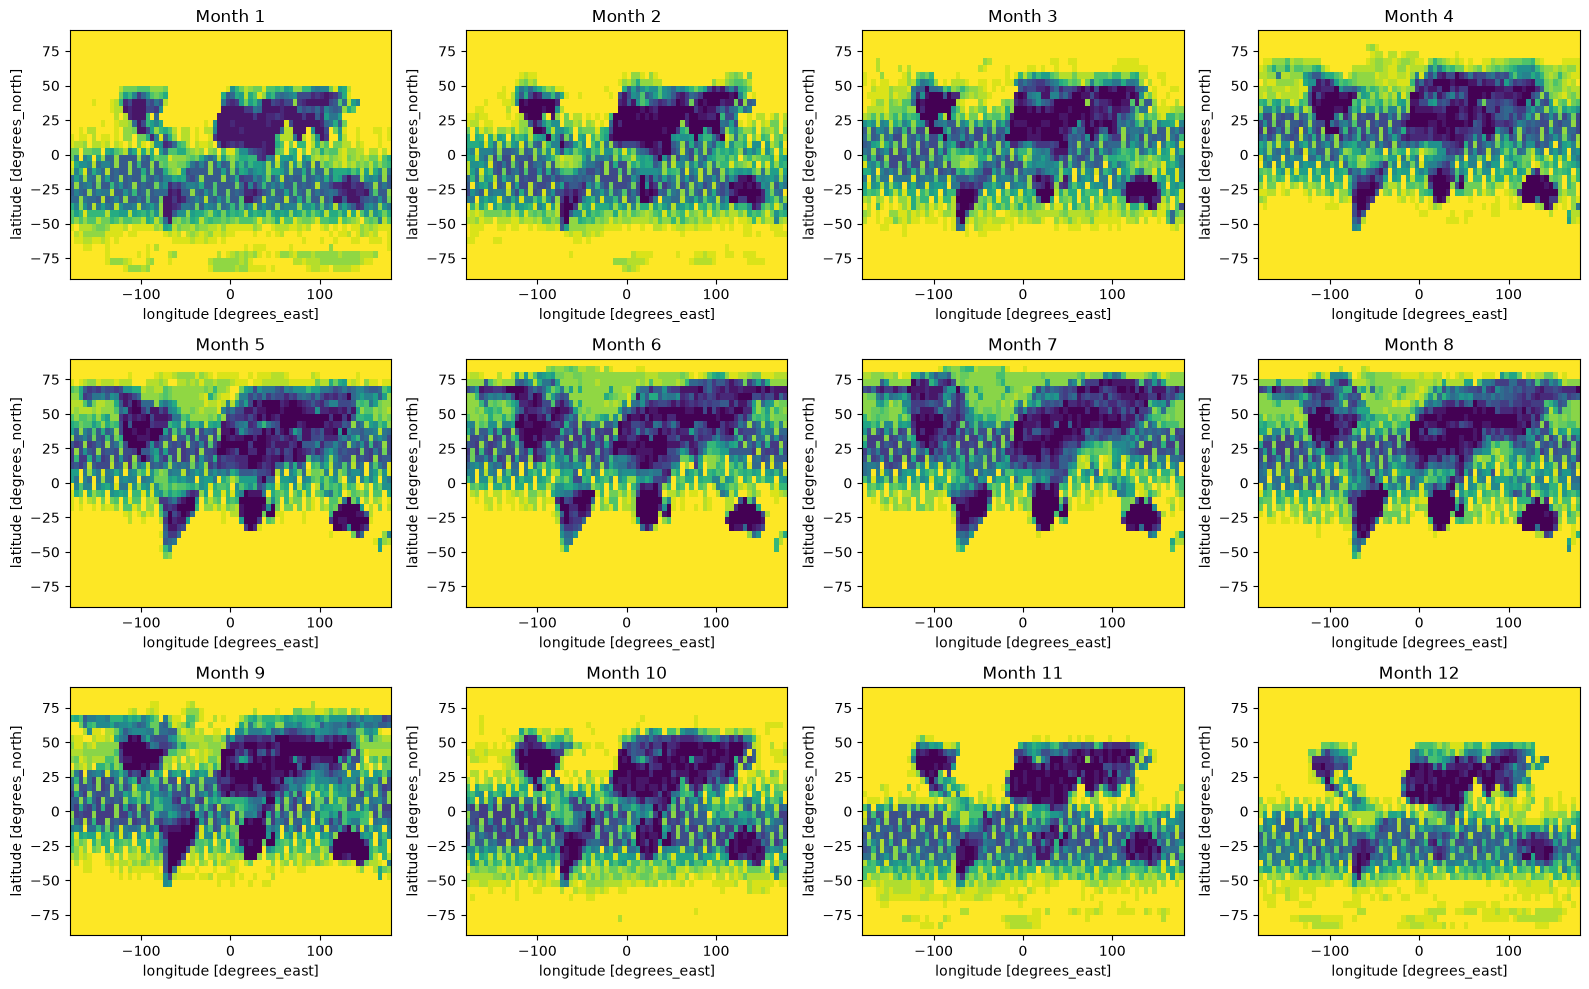

In [4]:
#计算甲烷的climatology
ch4_clim = ch4.groupby('time.month').mean(dim='time')
ch4_clim

# 画图
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for i in range(12):

    ax = axes[i // 4, i % 4]

    ch4_clim.sel(month=i+1).plot(
        ax=ax,
        vmin=float(ch4_clim.min()),
        vmax=float(ch4_clim.max()),
        cmap='viridis',
        add_colorbar=False
    )

    ax.set_title('Month ' + str(i+1))

plt.tight_layout()
plt.show()

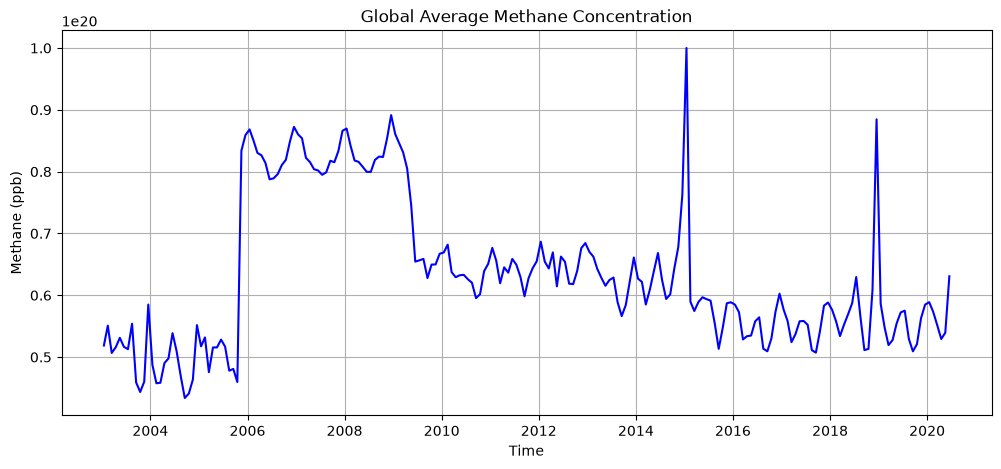

In [27]:
# 计算纬度权重
weights = np.cos(np.deg2rad(ch4['lat']))

# 计算全球加权平均甲烷浓度
ch4_weighted = ch4.weighted(weights)
global_ch4 = ch4_weighted.mean(dim=('lon', 'lat'))

# 画图
global_ch4.sel(time=slice("2003-01", "2020-06")).plot(figsize=(12, 5), color='blue')
plt.xlabel('Time')
plt.ylabel('Methane (ppb)')
plt.title('Global Average Methane Concentration')
plt.grid()
plt.show()

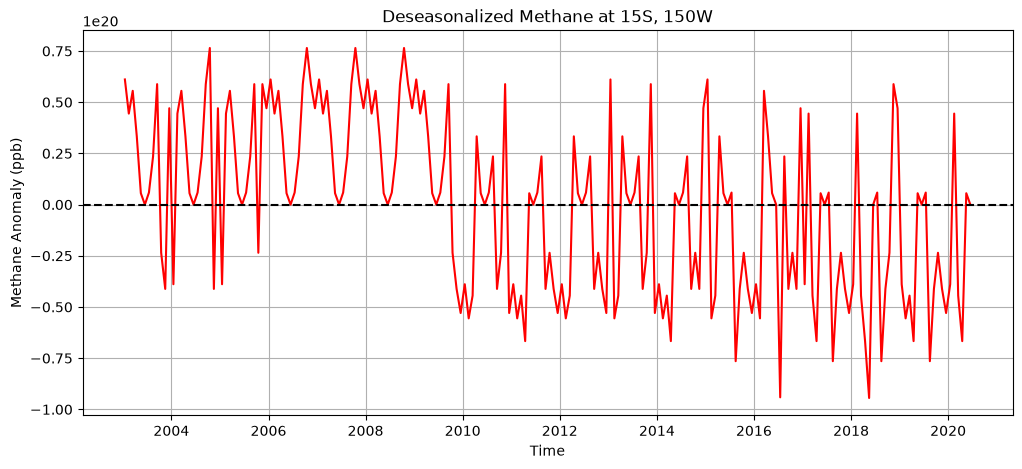

In [26]:
#计算point [15°S, 150°W]的甲烷climatology
ch4_point = ch4.sel(
    lon=210,
    lat=-15,
    method='nearest'
)
ch4_point
group_data = ch4_point.groupby('time.month')
ch4_clim_point = group_data.mean(dim='time')

#去季节化
ch4_anom = group_data - ch4_clim_point
ch4_anom


# 画图
ch4_anom.plot(figsize=(12, 5), color='red')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Time')
plt.ylabel('Methane Anomaly (ppb)')
plt.title('Deseasonalized Methane at 15S, 150W')
plt.grid()
plt.show()

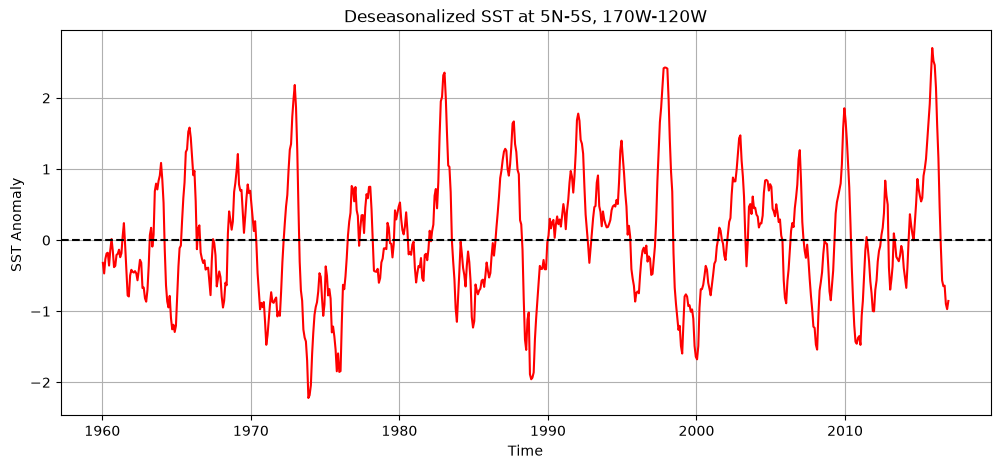

In [25]:
# 1.打开nc文件，提取sst数据
ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
ds

sst = ds.sst
sst


# 选择 Niño 3.4 区域
nino_region = sst.where(
    (sst.lat >= -5) &
    (sst.lat <= 5) &
    (sst.lon >= 190) &
    (sst.lon <= 240),
    drop=True
)
nino_region


# 计算纬度权重
weights = np.cos(np.deg2rad(nino_region.lat))
weights


# 计算区域平均sst
nino_sst = nino_region.weighted(weights).mean(
    dim=('lon', 'lat')
)
nino_sst

# 计算每个月的多年平均sst
nino_clim = nino_sst.groupby('time.month').mean(dim='time')
nino_clim


# 计算SST异常
group_data = nino_sst.groupby('time.month')
nino_anom = group_data - nino_clim
nino_anom

#画图
nino_anom.plot(figsize=(12, 5), color='red')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Time')
plt.ylabel('SST Anomaly ')
plt.title('Deseasonalized SST at 5N-5S, 170W-120W')
plt.grid()
plt.show()

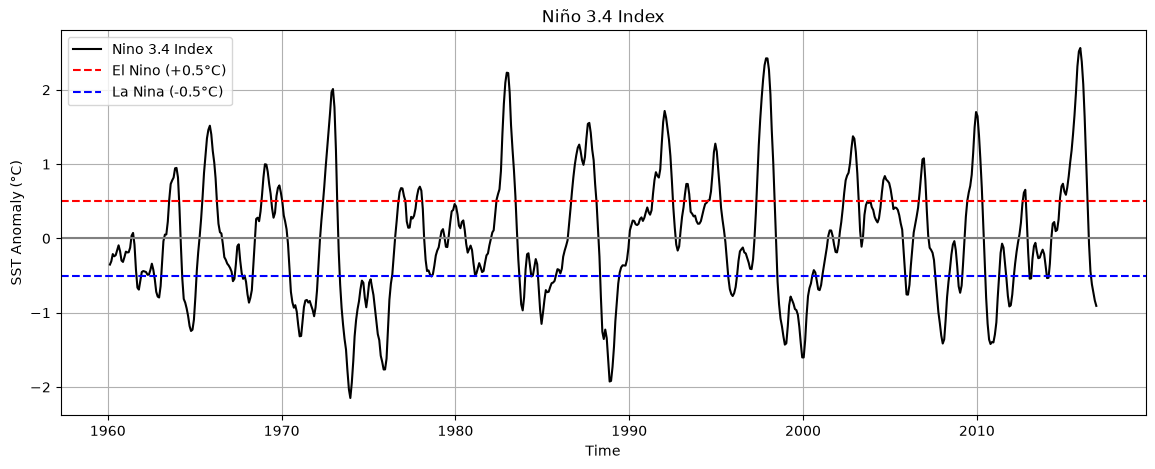

In [14]:
# 计算3个月滑动平均
nino34 = nino_anom.rolling(
    time=3,
    center=True
).mean()
nino34


# 画图
nino34.plot(
    figsize=(14, 5),
    color='black',
    label='Nino 3.4 Index'
)

plt.axhline(
    0.5,
    color='red',
    linestyle='--',
    label='El Nino (+0.5°C)'
)

plt.axhline(
    -0.5,
    color='blue',
    linestyle='--',
    label='La Nina (-0.5°C)'
)


plt.axhline(0, color='gray')
plt.xlabel('Time')
plt.ylabel('SST Anomaly (°C)')
plt.title('Niño 3.4 Index')
plt.legend()
plt.grid()
plt.show()

D:\anacanda\Lib\site-packages\xarray\conventions.py:205: SerializationWarning: variable 'tas' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)


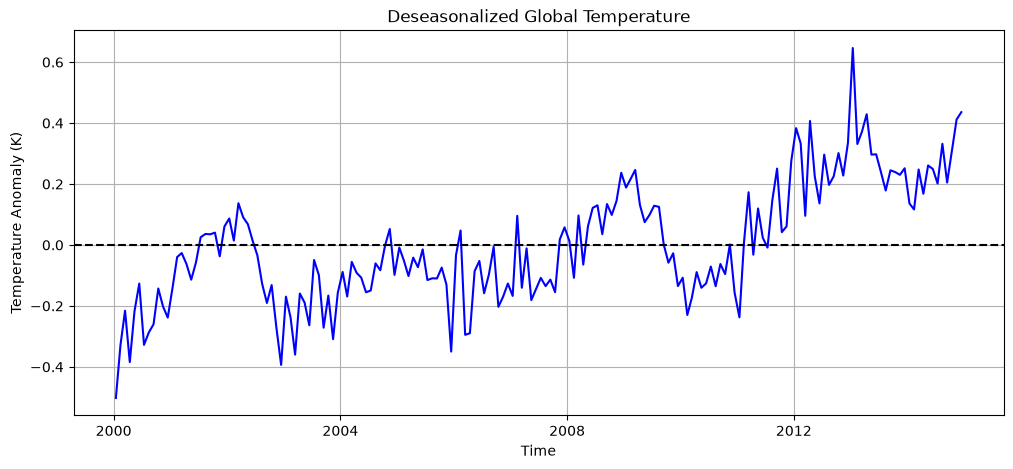

In [18]:
#读取nc文件，提取气温数据
ds = xr.open_dataset("CESM2_200001-201412.nc")
ds

tas = ds.tas
tas


# 计算纬度权重
weights = np.cos(np.deg2rad(ds.lat))
weights


#计算全球气温加权平均值
tas_weighted = tas.weighted(weights)
global_tas = tas_weighted.mean(dim=('lon', 'lat'))
global_tas


# 计算每月的climatology
tas_clim = global_tas.groupby('time.month').mean(dim='time')
tas_clim


#计算异常
group_data = global_tas.groupby('time.month')
tas_anom = group_data - group_data.mean(dim='time')
tas_anom


# 画图
tas_anom.plot(figsize=(12, 5), color='blue')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Time')
plt.ylabel('Temperature Anomaly (K)')
plt.title('Deseasonalized Global Temperature')
plt.grid()
plt.show()

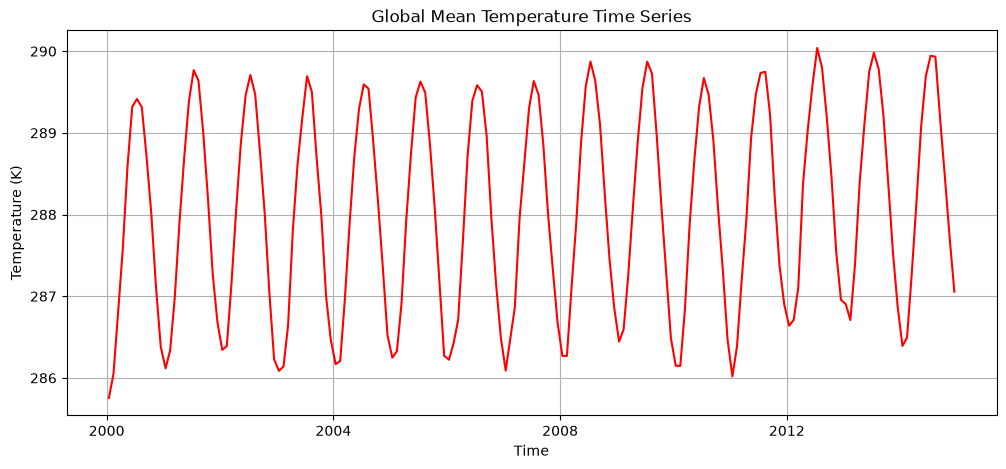

In [19]:
#全球平均气温时间序列图
# 计算全球平均气温
weights = np.cos(np.deg2rad(ds.lat))
tas_weighted = tas.weighted(weights)
global_tas = tas_weighted.mean(dim=('lon', 'lat'))


global_tas.plot(figsize=(12, 5), color='red')
plt.xlabel('Time')
plt.ylabel('Temperature (K)')
plt.title('Global Mean Temperature Time Series')
plt.grid()
plt.show()

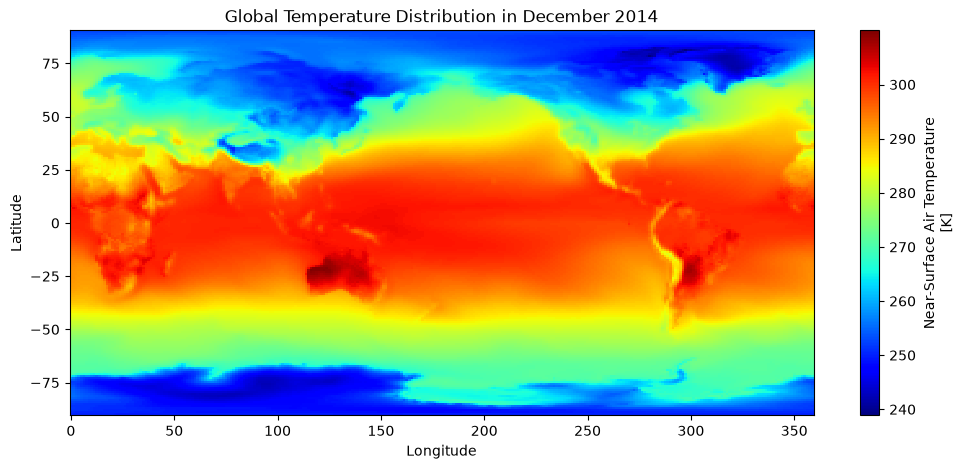

In [24]:
#最新月份的全球气温空间分布图
tas[-1].plot(
    figsize=(12, 5),
    cmap='jet'
)

plt.title('Global Temperature Distribution in December 2014')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

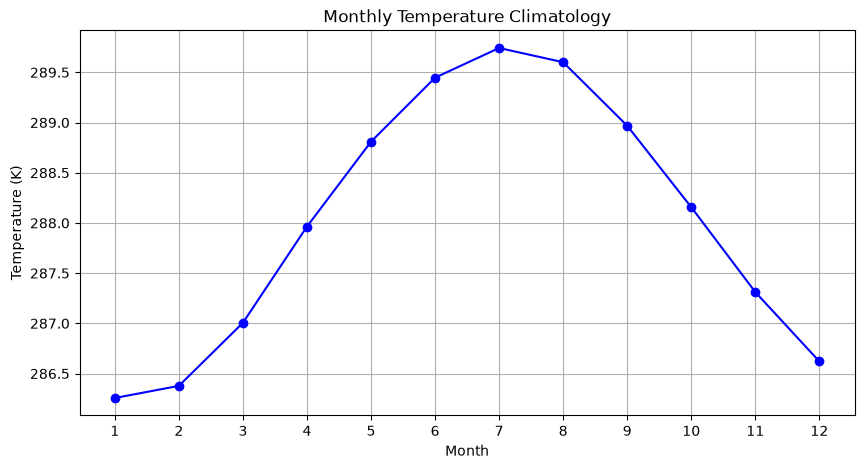

In [22]:
#12个月的气温气候平均值
tas_clim = tas.groupby('time.month').mean(dim='time')
tas_clim_global = tas_clim.weighted(weights).mean(
    dim=('lon', 'lat')
)

tas_clim_global.plot(
    figsize=(10, 5),
    marker='o',
    color='blue'
)

plt.xlabel('Month')
plt.ylabel('Temperature (K)')
plt.title('Monthly Temperature Climatology')
plt.xticks(range(1, 13))
plt.grid()
plt.show()

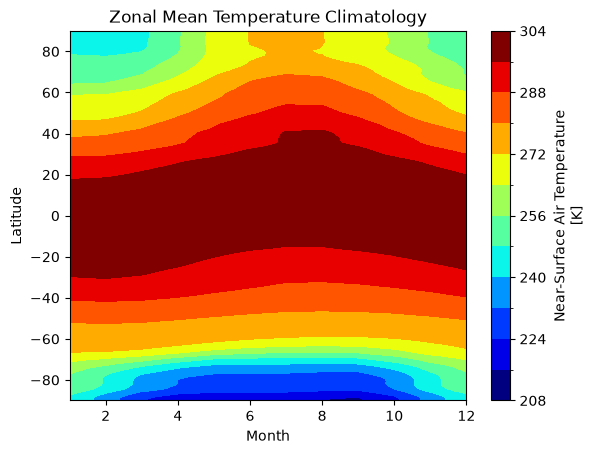

In [23]:
#纬向平均气温分布图
tas_zonal = tas_clim.mean(dim='lon')
tas_zonal.plot.contourf(
    x='month',
    levels=12,
    cmap='jet'
)

plt.xlabel('Month')
plt.ylabel('Latitude')
plt.title('Zonal Mean Temperature Climatology')
plt.show()

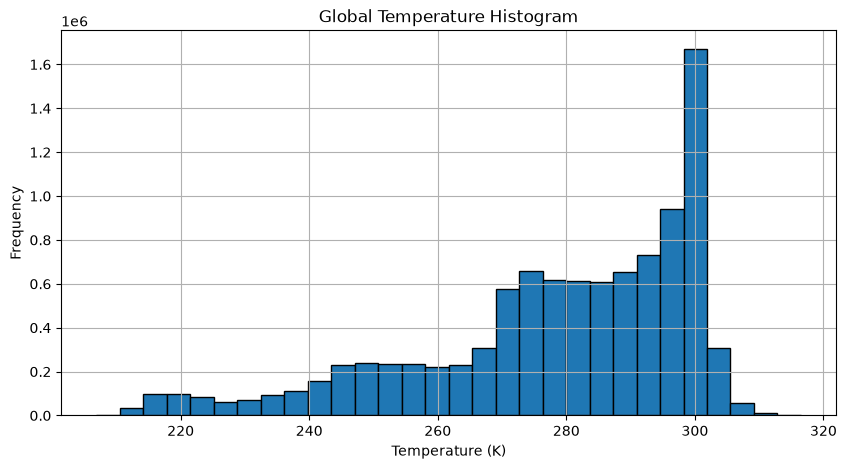

In [28]:
#全球气温直方图
tas_values = tas.values.flatten()

# 除去缺失值
tas_values = tas_values[np.isfinite(tas_values)]

plt.figure(figsize=(10, 5))
plt.hist(
    tas_values,
    bins=30,
    edgecolor='black'
)

plt.xlabel('Temperature (K)')
plt.ylabel('Frequency')
plt.title('Global Temperature Histogram')
plt.grid()
plt.show()